# K-nearest neighbors

Study how the neighbor count affects classification after feature scaling.

**Dataset:** `data/student_data.csv` (395 student records, 33 columns). **Target:** final grade `G3` (0–20). For classification labs, pass means `G3 ≥ 10`. Earlier grades `G1` and `G2` are included as predictors; interpret results as prediction after those earlier grades are known. The split is fixed with random seed 42 for reproducibility.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATHS = [Path("data/student_data.csv"), Path("../data/student_data.csv")]
DATA_PATH = next((p for p in DATA_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place student_data.csv in the repository's data/ folder.")
df = pd.read_csv(DATA_PATH)
TARGET = "G3"  # final-period grade (0–20)
PASS_THRESHOLD = 10
numeric_features = df.select_dtypes(include=np.number).columns.drop(TARGET).tolist()
categorical_features = df.select_dtypes(exclude=np.number).columns.tolist()
feature_cols = numeric_features + categorical_features
X = df[feature_cols]
y_reg = df[TARGET]
y_class = (df[TARGET] >= PASS_THRESHOLD).astype(int)


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def make_preprocessor(scale_numeric=True):
    numeric_steps = [("scale", StandardScaler())] if scale_numeric else []
    numeric_pipe = Pipeline(numeric_steps) if numeric_steps else "passthrough"
    return ColumnTransformer(
        [("numeric", numeric_pipe, numeric_features),
         ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
        remainder="drop",
    )


,k,accuracy,macro_f1
0,3,0.747475,0.692049
1,5,0.747475,0.692049
2,7,0.777778,0.726107
3,9,0.767677,0.710490
4,11,0.767677,0.703709
5,15,0.737374,0.652162


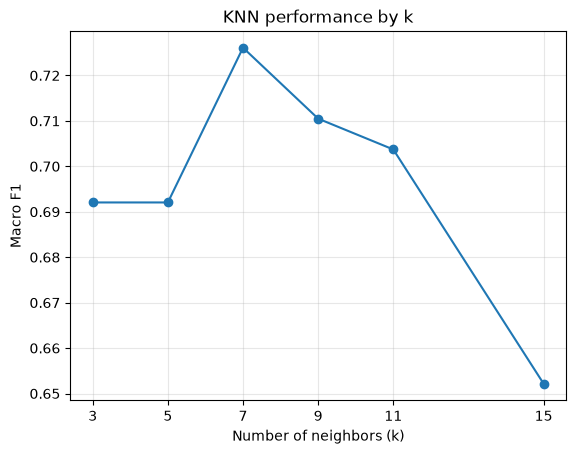

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.25, stratify=y_class, random_state=42)
rows=[]
for k in [3,5,7,9,11,15]:
    pipe=Pipeline([("preprocess",make_preprocessor()),("classifier",KNeighborsClassifier(n_neighbors=k,weights="distance"))])
    pipe.fit(X_train,y_train); pred=pipe.predict(X_test)
    rows.append({"k":k,"accuracy":accuracy_score(y_test,pred),"macro_f1":f1_score(y_test,pred,average="macro")})
results=pd.DataFrame(rows); display(results)
plt.plot(results.k,results.macro_f1,marker="o"); plt.xticks(results.k)
plt.xlabel("Number of neighbors (k)"); plt.ylabel("Macro F1"); plt.title("KNN performance by k"); plt.grid(alpha=.3); plt.show()
